<a href="https://colab.research.google.com/github/anthony-yt/deepwater-image-segmentation-classical-quantum/blob/feat%2Fground-truth-reconciliation/notebooks/2_1_ground_truth_reconciliation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
import hashlib
import json
import os
import re
import shutil
import sys
from datetime import date
from itertools import combinations
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
from PIL import Image

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive

    drive.mount("/content/drive")
    DRIVE_ROOT = Path("/content/drive/MyDrive/Under_Water_Dataset")
else:
    DRIVE_ROOT = Path(os.environ.get("DW_DATA_ROOT", "Under_Water_Dataset")).resolve()

PROCESSED_DIR = DRIVE_ROOT / "Dataset_Processed"
FRAMES_DIR = PROCESSED_DIR / "Frames_CLAHE"
GROUND_TRUTH_DIR = PROCESSED_DIR / "Ground_Truth"

V1_CANDIDATES = [PROCESSED_DIR / "SAM_Auto_Mask", DRIVE_ROOT / "SAM_Auto_Mask",
                 GROUND_TRUTH_DIR / "archive" / "v1_sam_auto_pps32_2026-09-09"]

VERSIONS = {
    "v1_sam_auto": {
        "label": "v1 · SAM automatic",
        "dir": next((d for d in V1_CANDIDATES if d.is_dir()), V1_CANDIDATES[0]),
        "origin": "SamAutomaticMaskGenerator, ViT-B, points_per_side=32, 9 Sep 2026",
    },
    "v2_curated": {
        "label": "v2 · hand-curated",
        "dir": PROCESSED_DIR / "Test_Set_Curado",
        "origin": "manual curation, Sprint 3 audit, 11-19 Sep 2026",
    },
    "v3_sam_points": {
        "label": "v3 · SAM fixed points",
        "dir": PROCESSED_DIR / "SAM_Masks_Frames_CLAHE",
        "origin": "SamPredictor, same 3 centre points on every frame, 25 Sep 2026",
    },
}
REFERENCE = "v2_curated"
BIN_THRESHOLD = 127
SEED = 42

SERIES_COLOR = {"v1_sam_auto": "#2a78d6", "v2_curated": "#eb6834", "v3_sam_points": "#1baf7a"}
INK, INK_SOFT, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## Locate the three versions

In [4]:
IMAGE_EXTENSIONS = {".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"}

def frame_key(path) -> str:
    stem = re.sub(r"\s*\(\d+\)$", "", Path(path).stem)
    return re.sub(r"_mask$", "", stem, flags=re.IGNORECASE)

def index_dir(directory: Path) -> dict:
    index = {}
    if not directory.is_dir():
        return index
    for path in sorted(directory.iterdir()):
        if path.suffix.lower() not in IMAGE_EXTENSIONS:
            continue
        key = frame_key(path)
        if key not in index or path.stem.lower().endswith("_mask"):
            index[key] = path
    return index

files = {name: index_dir(cfg["dir"]) for name, cfg in VERSIONS.items()}
frame_files = index_dir(FRAMES_DIR)

for name, cfg in VERSIONS.items():
    print(f"{name:14s} {len(files[name]):4d} files   {cfg['dir']}")
print(f"{'CLAHE frames':14s} {len(frame_files):4d} files   {FRAMES_DIR}")

empty = [name for name in VERSIONS if not files[name]]
if empty:
    raise FileNotFoundError(
        f"No mask files found for: {empty}. v1 is expected in any of {[str(d) for d in V1_CANDIDATES]}."
    )

FRAME_IDS = sorted(set.intersection(*(set(index) for index in files.values())))
print(f"\nFrames present in all {len(VERSIONS)} versions: {len(FRAME_IDS)}")
if not FRAME_IDS:
    raise RuntimeError("The three versions share no frame id. Check the file names.")

v1_sam_auto      20 files   /content/drive/MyDrive/Under_Water_Dataset/Dataset_Processed/SAM_Auto_Mask
v2_curated       20 files   /content/drive/MyDrive/Under_Water_Dataset/Dataset_Processed/Test_Set_Curado
v3_sam_points   105 files   /content/drive/MyDrive/Under_Water_Dataset/Dataset_Processed/SAM_Masks_Frames_CLAHE
CLAHE frames    249 files   /content/drive/MyDrive/Under_Water_Dataset/Dataset_Processed/Frames_CLAHE

Frames present in all 3 versions: 20


## How the masks are stored

In [5]:
def read_gray(path) -> np.ndarray:
    image = cv2.imdecode(np.fromfile(str(path), dtype=np.uint8), cv2.IMREAD_UNCHANGED)
    if image is None:
        raise ValueError(f"Unreadable mask: {path}")
    if image.dtype == np.uint16:
        image = (image >> 8).astype(np.uint8)
    if image.ndim == 3:
        image = image[..., :3].max(axis=2)
    return image

def binarize(gray: np.ndarray, threshold: int = BIN_THRESHOLD) -> np.ndarray:
    if gray.max() <= 1:
        return gray.astype(bool)
    return gray > threshold

def describe_file(path) -> dict:
    with Image.open(path) as image:
        storage = image.mode
        index0_is_white = None
        if storage == "P":
            palette = image.getpalette() or [0, 0, 0]
            index0_is_white = min(palette[:3]) > 127
    gray = read_gray(path)
    return {
        "storage": storage,
        "grey_levels": int(len(np.unique(gray))),
        "palette_index0_is_white": index0_is_white,
        "fg_if_any_nonzero": float((gray > 0).mean()),
        "fg_thresholded": float(binarize(gray).mean()),
        "height": gray.shape[0],
        "width": gray.shape[1],
    }

file_audit = pd.DataFrame(
    [{"version": name, "frame": fid, "file": files[name][fid].name, **describe_file(files[name][fid])}
     for name in VERSIONS for fid in FRAME_IDS]
)
file_audit["rule_gap"] = (file_audit.fg_if_any_nonzero - file_audit.fg_thresholded).abs()

storage_summary = file_audit.groupby("version", sort=False).agg(
    files=("frame", "size"),
    storage_modes=("storage", lambda s: ", ".join(f"{mode}×{count}" for mode, count in s.value_counts().items())),
    not_strictly_binary=("grey_levels", lambda s: int((s > 2).sum())),
    inverted_palette=("palette_index0_is_white", lambda s: int((s == True).sum())),  # noqa: E712
    max_gap_between_rules=("rule_gap", "max"),
)
display(storage_summary)

problem_files = file_audit[(file_audit.grey_levels > 2) | (file_audit.palette_index0_is_white == True)]  # noqa: E712
display(problem_files[["version", "frame", "storage", "grey_levels", "palette_index0_is_white",
                       "fg_if_any_nonzero", "fg_thresholded"]].reset_index(drop=True))

,files,storage_modes,not_strictly_binary,inverted_palette,max_gap_between_rules
version,,,,,
v1_sam_auto,20,L×20,0,0,0.000000
v2_curated,20,"P×19, RGB×1",3,6,0.003785
v3_sam_points,20,L×20,0,0,0.000000


,version,frame,storage,grey_levels,palette_index0_is_white,fg_if_any_nonzero,fg_thresholded
0,v2_curated,DeepWater-Video1_frame_0000,P,25,False,0.598811,0.598511
1,v2_curated,DeepWater-Video1_frame_0013,P,2,True,0.780252,0.780252
2,v2_curated,DeepWater-Video1_frame_0014,P,2,True,0.770056,0.770056
3,v2_curated,DeepWater-Video1_frame_0015,P,2,True,0.788702,0.788702
4,v2_curated,DeepWater-Video1_frame_0016,P,2,True,0.815803,0.815803
5,v2_curated,DeepWater-Video1_frame_0017,P,2,True,0.770595,0.770595
6,v2_curated,DeepWater-Video1_frame_0018,RGB,241,None,0.813168,0.809384
7,v2_curated,DeepWater-Video1_frame_0019,P,197,True,0.911024,0.910187


In [6]:
def content_hash(mask: np.ndarray) -> str:
    digest = hashlib.sha256(str(mask.shape).encode())
    digest.update(np.packbits(mask.astype(np.uint8)).tobytes())
    return digest.hexdigest()[:16]

masks = {name: {fid: binarize(read_gray(files[name][fid])) for fid in FRAME_IDS} for name in VERSIONS}

shape_problems = [
    (fid, {name: masks[name][fid].shape for name in VERSIONS})
    for fid in FRAME_IDS
    if len({masks[name][fid].shape for name in VERSIONS}) > 1
]
if shape_problems:
    raise ValueError(f"Versions disagree on image size for {len(shape_problems)} frames: {shape_problems[:3]}")

set_hash = {
    name: hashlib.sha256("".join(content_hash(masks[name][fid]) for fid in FRAME_IDS).encode()).hexdigest()[:16]
    for name in VERSIONS
}

EXPECTED_SET_HASH = {
    "v1_sam_auto": "07908a7601f9a278",
    "v2_curated": "b90aaeb043004c34",
    "v3_sam_points": "5e9c601fd84b2907",
}
for name in VERSIONS:
    status = "matches the 2026-10-04 analysis" if set_hash[name] == EXPECTED_SET_HASH[name] else "DIFFERENT from the 2026-10-04 analysis"
    print(f"{name:14s} {set_hash[name]}   {status}")

identical_pairs = [(a, b) for a, b in combinations(VERSIONS, 2)
                   if all(np.array_equal(masks[a][fid], masks[b][fid]) for fid in FRAME_IDS)]
if identical_pairs:
    raise RuntimeError(
        f"These versions are pixel-identical: {identical_pairs}. The v1 folder probably contains the "
        "overwritten masks from SAM_Masks_Frames_CLAHE instead of the archived 9 Sep files."
    )

v1_sam_auto    07908a7601f9a278   matches the 2026-10-04 analysis
v2_curated     b90aaeb043004c34   matches the 2026-10-04 analysis
v3_sam_points  5e9c601fd84b2907   matches the 2026-10-04 analysis


## How much do the versions disagree?

In [7]:
def iou(a: np.ndarray, b: np.ndarray) -> float:
    union = np.logical_or(a, b).sum()
    return float(np.logical_and(a, b).sum() / union) if union else 1.0

def dice(a: np.ndarray, b: np.ndarray) -> float:
    total = a.sum() + b.sum()
    return float(2.0 * np.logical_and(a, b).sum() / total) if total else 1.0

def precision_recall(candidate: np.ndarray, reference: np.ndarray) -> tuple:
    true_positive = np.logical_and(candidate, reference).sum()
    precision = float(true_positive / candidate.sum()) if candidate.sum() else float("nan")
    recall = float(true_positive / reference.sum()) if reference.sum() else float("nan")
    return precision, recall

def bootstrap_ci(values, n_boot: int = 10_000, alpha: float = 0.05, seed: int = SEED) -> tuple:
    values = np.asarray(values, dtype=float)
    rng = np.random.default_rng(seed)
    means = rng.choice(values, size=(n_boot, len(values)), replace=True).mean(axis=1)
    low, high = np.quantile(means, [alpha / 2, 1 - alpha / 2])
    return float(low), float(high)

def summarise(frame: pd.DataFrame, by: str, metrics: list) -> pd.DataFrame:
    rows = []
    for key, group in frame.groupby(by, sort=False):
        row = {by: key, "frames": len(group)}
        for metric in metrics:
            values = group[metric].dropna()
            if values.empty:
                row.update({f"{metric}_{stat}": float("nan") for stat in ("mean", "sd", "median", "min", "max")})
                row[f"{metric}_ci95"] = "n/a"
                continue
            low, high = bootstrap_ci(values)
            row.update({
                f"{metric}_mean": values.mean(), f"{metric}_sd": values.std(ddof=1),
                f"{metric}_median": values.median(), f"{metric}_min": values.min(), f"{metric}_max": values.max(),
                f"{metric}_ci95": f"[{low:.3f}, {high:.3f}]",
            })
        rows.append(row)
    return pd.DataFrame(rows).set_index(by)

pairwise = pd.DataFrame(
    [{"frame": fid, "pair": f"{a} vs {b}", "iou": iou(masks[a][fid], masks[b][fid]),
      "dice": dice(masks[a][fid], masks[b][fid])}
     for fid in FRAME_IDS for a, b in combinations(VERSIONS, 2)]
)
pairwise_summary = summarise(pairwise, "pair", ["iou", "dice"])
display(pairwise_summary.round(3))

,frames,iou_mean,iou_sd,iou_median,iou_min,iou_max,iou_ci95,dice_mean,dice_sd,dice_median,dice_min,dice_max,dice_ci95
pair,,,,,,,,,,,,,
v1_sam_auto vs v2_curated,20,0.235,0.177,0.187,0.073,0.682,"[0.168, 0.316]",0.354,0.193,0.315,0.135,0.811,"[0.279, 0.442]"
v1_sam_auto vs v3_sam_points,20,0.281,0.306,0.178,0.038,0.995,"[0.164, 0.421]",0.374,0.290,0.302,0.073,0.997,"[0.259, 0.503]"
v2_curated vs v3_sam_points,20,0.664,0.165,0.645,0.385,0.956,"[0.594, 0.736]",0.787,0.121,0.784,0.556,0.978,"[0.734, 0.838]"


In [8]:
reference_rows = []
for fid in FRAME_IDS:
    reference = masks[REFERENCE][fid]
    candidates = {name: masks[name][fid] for name in VERSIONS if name != REFERENCE}
    candidates["baseline_all_structure"] = np.ones_like(reference)
    candidates["baseline_all_background"] = np.zeros_like(reference)
    for name, candidate in candidates.items():
        precision, recall = precision_recall(candidate, reference)
        reference_rows.append({"frame": fid, "candidate": name, "iou": iou(candidate, reference),
                               "dice": dice(candidate, reference), "precision": precision, "recall": recall})
vs_reference = pd.DataFrame(reference_rows)
vs_reference_summary = summarise(vs_reference, "candidate", ["iou", "dice", "precision", "recall"])
display(vs_reference_summary[[c for c in vs_reference_summary.columns
                              if c.endswith(("_mean", "_sd", "_median")) or c == "iou_ci95"]].round(3))

iou_wide = vs_reference.pivot(index="frame", columns="candidate", values="iou")
beats_trivial = pd.DataFrame({
    name: {
        "frames_better_than_all_structure": int((iou_wide[name] > iou_wide["baseline_all_structure"]).sum()),
        "mean_iou_gain_over_all_structure": float((iou_wide[name] - iou_wide["baseline_all_structure"]).mean()),
    }
    for name in VERSIONS if name != REFERENCE
}).T
beats_trivial["frames"] = len(FRAME_IDS)
display(beats_trivial.round(3))

,iou_mean,iou_sd,iou_median,iou_ci95,dice_mean,dice_sd,dice_median,precision_mean,precision_sd,precision_median,recall_mean,recall_sd,recall_median
candidate,,,,,,,,,,,,,
v1_sam_auto,0.235,0.177,0.187,"[0.168, 0.316]",0.354,0.193,0.315,0.732,0.208,0.812,0.295,0.284,0.190
v3_sam_points,0.664,0.165,0.645,"[0.594, 0.736]",0.787,0.121,0.784,0.742,0.149,0.682,0.874,0.171,0.956
baseline_all_structure,0.718,0.082,0.708,"[0.684, 0.753]",0.833,0.055,0.829,0.718,0.082,0.708,1.000,0.000,1.000
baseline_all_background,0.000,0.000,0.000,"[0.000, 0.000]",0.000,0.000,0.000,NaN,NaN,NaN,0.000,0.000,0.000


,frames_better_than_all_structure,mean_iou_gain_over_all_structure,frames
v1_sam_auto,0.0,-0.483,20
v3_sam_points,6.0,-0.054,20


In [9]:
def count_components(mask: np.ndarray) -> int:
    n_labels, _ = cv2.connectedComponents(mask.astype(np.uint8), connectivity=4)
    return n_labels - 1

shape_rows = []
for name in VERSIONS:
    for fid in FRAME_IDS:
        mask = masks[name][fid]
        shape_rows.append({"version": name, "frame": fid, "foreground_fraction": float(mask.mean()),
                           "components": count_components(mask)})
shape_stats = pd.DataFrame(shape_rows)
version_profile = shape_stats.groupby("version", sort=False).agg(
    foreground_mean=("foreground_fraction", "mean"),
    foreground_min=("foreground_fraction", "min"),
    foreground_max=("foreground_fraction", "max"),
    frames_almost_all_foreground=("foreground_fraction", lambda s: int((s >= 0.98).sum())),
    components_median=("components", "median"),
    components_max=("components", "max"),
)
display(version_profile.round(3))

votes = {fid: sum(masks[name][fid].astype(np.uint8) for name in VERSIONS) for fid in FRAME_IDS}
vote_share = pd.Series(np.concatenate([v.ravel() for v in votes.values()])).value_counts(normalize=True).sort_index()
vote_share.index = [f"{k} of {len(VERSIONS)} versions say structure" for k in vote_share.index]
display(vote_share.round(3).to_frame("share_of_pixels"))
unanimous = float(vote_share.iloc[0] + vote_share.iloc[-1])
print(f"All three versions agree on {unanimous:.1%} of the pixels.")

,foreground_mean,foreground_min,foreground_max,frames_almost_all_foreground,components_median,components_max
version,,,,,,
v1_sam_auto,0.320,0.096,0.998,2,43.0,69
v2_curated,0.718,0.559,0.910,0,1.0,1
v3_sam_points,0.855,0.365,0.992,5,30.5,120


,share_of_pixels
0 of 3 versions say structure,0.032
1 of 3 versions say structure,0.217
2 of 3 versions say structure,0.577
3 of 3 versions say structure,0.174


All three versions agree on 20.6% of the pixels.


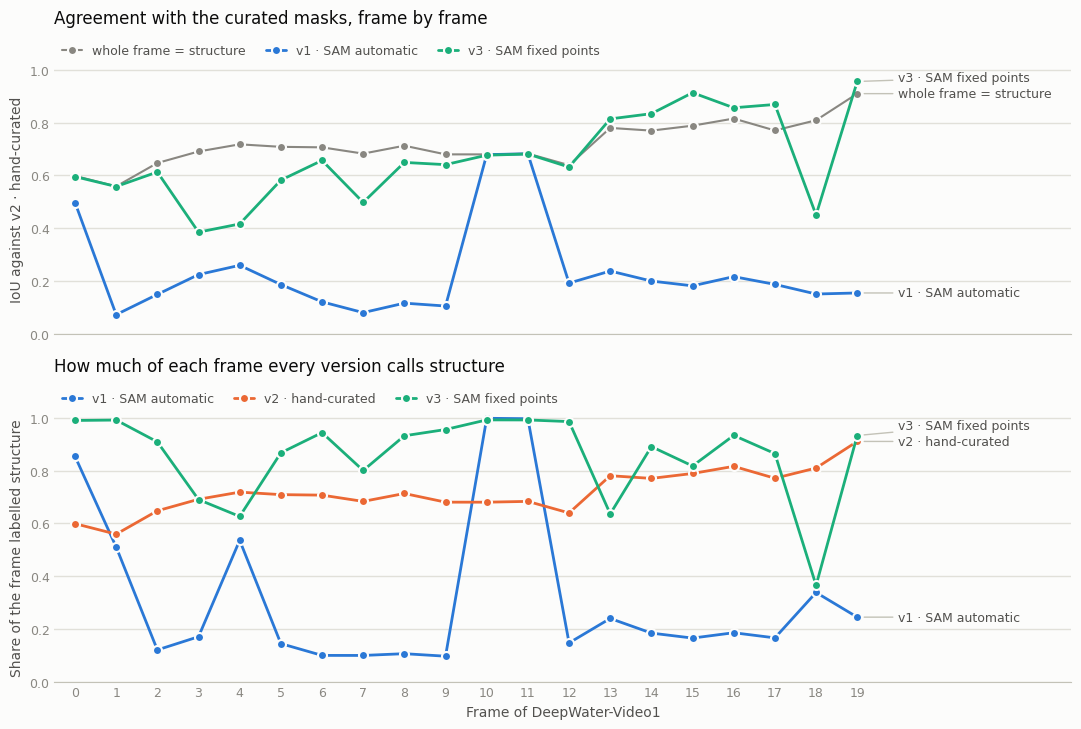

In [10]:
def style_axis(ax, ylabel: str) -> None:
    ax.set_facecolor(SURFACE)
    ax.grid(axis="y", color=GRID, linewidth=1)
    ax.set_axisbelow(True)
    for side in ("top", "right", "left"):
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color(AXIS)
    ax.tick_params(colors=MUTED, length=0, labelsize=9)
    ax.set_ylabel(ylabel, color=INK_SOFT, fontsize=10)
    ax.set_ylim(0, 1.02)

def plot_series(ax, x, y, color: str, label: str, linewidth: float = 2.0) -> tuple:
    ax.plot(x, y, color=color, linewidth=linewidth, marker="o", markersize=6.5, markeredgecolor=SURFACE,
            markeredgewidth=1.5, solid_capstyle="round", solid_joinstyle="round", label=label)
    return float(y[-1]), label

def label_line_ends(ax, x_last: float, ends: list, min_gap: float = 0.06) -> None:
    ordered = sorted(ends)
    positions = []
    for y, _ in ordered:
        positions.append(y if not positions else max(y, positions[-1] + min_gap))
    overflow = positions[-1] - 1.0
    if overflow > 0:
        positions = [p - overflow for p in positions]
    for (y, text), y_text in zip(ordered, positions):
        ax.annotate(text, xy=(x_last, y), xytext=(x_last + 1.0, y_text), textcoords="data", va="center",
                    fontsize=9, color=INK_SOFT,
                    arrowprops={"arrowstyle": "-", "color": AXIS, "linewidth": 1, "shrinkA": 2, "shrinkB": 5})

def finish_axis(ax, title: str) -> None:
    ax.set_title(title, loc="left", fontsize=12, color=INK, pad=30)
    ax.legend(loc="lower left", bbox_to_anchor=(0, 1.0), frameon=False, fontsize=9, labelcolor=INK_SOFT,
              ncols=4, borderaxespad=0.2, handlelength=1.6, columnspacing=1.6)

frame_numbers = [int(fid.rsplit("_", 1)[-1]) for fid in FRAME_IDS]
fig, (ax_iou, ax_fg) = plt.subplots(2, 1, figsize=(11, 7.4), sharex=True, facecolor=SURFACE)

ends = [plot_series(ax_iou, frame_numbers, iou_wide.loc[FRAME_IDS, "baseline_all_structure"].to_numpy(), MUTED,
                    "whole frame = structure", linewidth=1.5)]
for name in VERSIONS:
    if name != REFERENCE:
        ends.append(plot_series(ax_iou, frame_numbers, iou_wide.loc[FRAME_IDS, name].to_numpy(),
                                SERIES_COLOR[name], VERSIONS[name]["label"]))
label_line_ends(ax_iou, frame_numbers[-1], ends)
style_axis(ax_iou, f"IoU against {VERSIONS[REFERENCE]['label']}")
finish_axis(ax_iou, "Agreement with the curated masks, frame by frame")

fg_wide = shape_stats.pivot(index="frame", columns="version", values="foreground_fraction")
ends = [plot_series(ax_fg, frame_numbers, fg_wide.loc[FRAME_IDS, name].to_numpy(), SERIES_COLOR[name],
                    VERSIONS[name]["label"]) for name in VERSIONS]
label_line_ends(ax_fg, frame_numbers[-1], ends)
style_axis(ax_fg, "Share of the frame labelled structure")
finish_axis(ax_fg, "How much of each frame every version calls structure")
ax_fg.set_xlabel("Frame of DeepWater-Video1", color=INK_SOFT, fontsize=10)
ax_fg.set_xticks(frame_numbers)
ax_fg.set_xlim(frame_numbers[0] - 0.5, frame_numbers[-1] + 5.2)

fig.tight_layout()
plt.show()

## Visual comparison

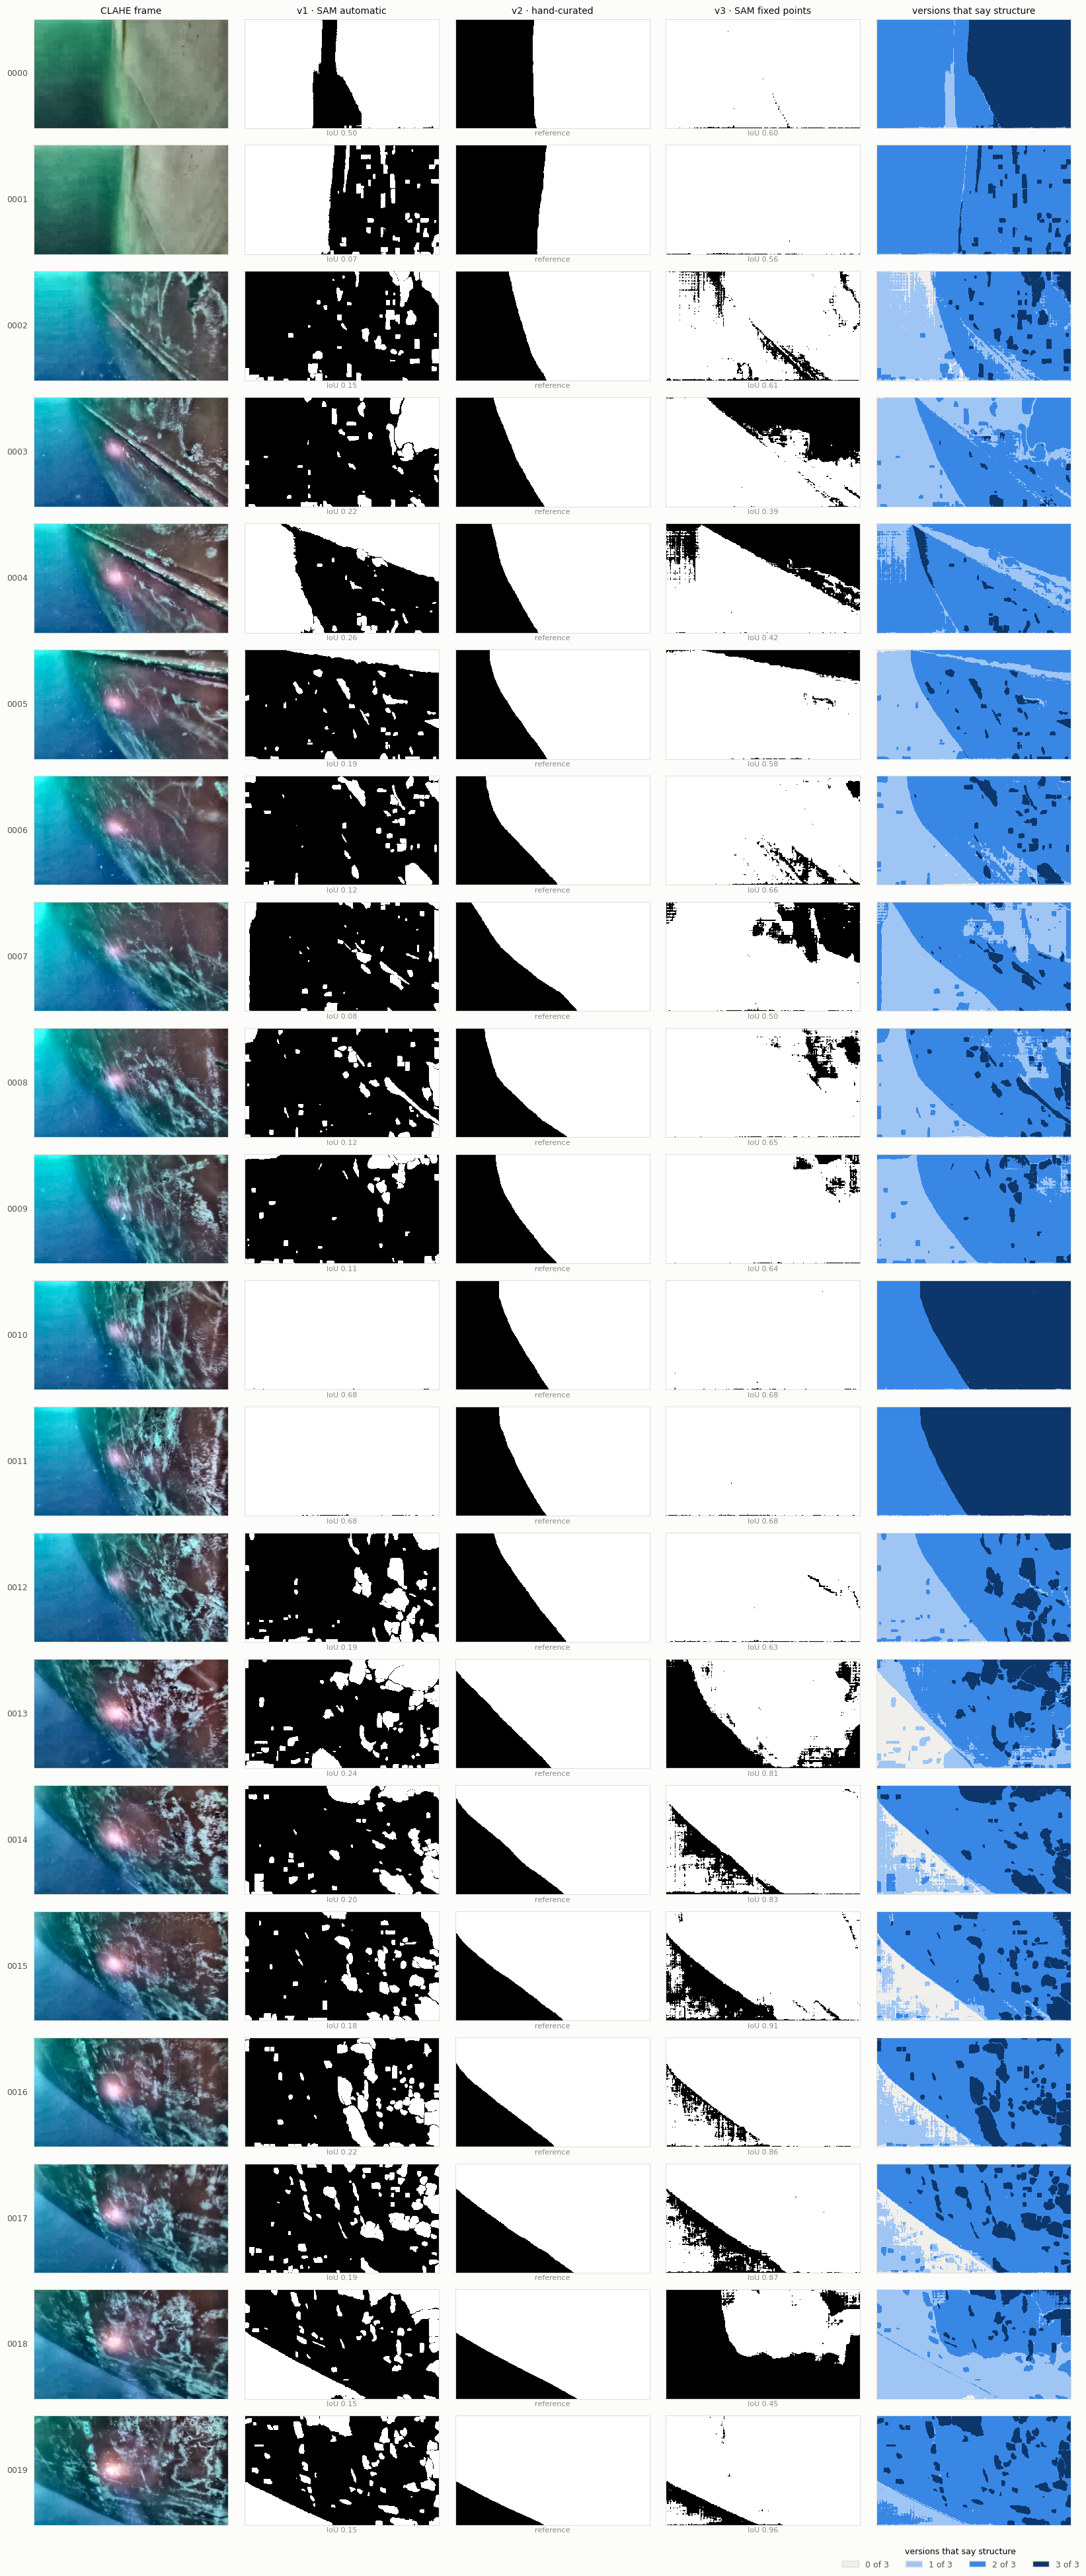

In [11]:
VOTE_COLORS = ["#f0efec", "#9ec5f4", "#3987e5", "#0d366b"]   # 0, 1, 2, 3 versions (one hue, light to dark)
vote_cmap = ListedColormap(VOTE_COLORS[: len(VERSIONS) + 1])

def read_frame_rgb(frame_id: str):
    path = frame_files.get(frame_id)
    if path is None:
        return None
    image = cv2.imdecode(np.fromfile(str(path), dtype=np.uint8), cv2.IMREAD_COLOR)
    return None if image is None else cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

columns = ["CLAHE frame"] + [VERSIONS[name]["label"] for name in VERSIONS] + ["versions that say structure"]
n_rows = len(FRAME_IDS)
fig, axes = plt.subplots(n_rows, len(columns), figsize=(3.3 * len(columns), 1.95 * n_rows), facecolor=SURFACE)
axes = np.atleast_2d(axes)
for row, fid in enumerate(FRAME_IDS):
    frame_rgb = read_frame_rgb(fid)
    if frame_rgb is not None:
        axes[row, 0].imshow(frame_rgb)
    axes[row, 0].set_ylabel(fid.rsplit("_", 1)[-1], rotation=0, labelpad=18, va="center", fontsize=9, color=INK_SOFT)
    for col, name in enumerate(VERSIONS, start=1):
        axes[row, col].imshow(masks[name][fid], cmap="gray", vmin=0, vmax=1, interpolation="nearest")
        score = "reference" if name == REFERENCE else f"IoU {iou_wide.loc[fid, name]:.2f}"
        axes[row, col].set_xlabel(score, fontsize=8, color=MUTED, labelpad=2)
    axes[row, -1].imshow(votes[fid], cmap=vote_cmap, vmin=0, vmax=len(VERSIONS), interpolation="nearest")
    for ax in axes[row]:
        ax.set_xticks([]); ax.set_yticks([])
        for spine in ax.spines.values():
            spine.set_color(GRID)
for col, title in enumerate(columns):
    axes[0, col].set_title(title, fontsize=10, color=INK)
fig.legend(handles=[Patch(facecolor=VOTE_COLORS[k], edgecolor=GRID, label=f"{k} of {len(VERSIONS)}")
                    for k in range(len(VERSIONS) + 1)],
           loc="lower right", ncols=len(VERSIONS) + 1, frameon=False, fontsize=9, labelcolor=INK_SOFT,
           title="versions that say structure", title_fontsize=9)
fig.tight_layout(rect=(0, 0.012, 1, 1))
plt.show()